# BCD experiments (Nour)

The optimizer is `recommender/bcd.py` (tests: `tests/test_bcd.py`): two blocks, `P` and
`(Q, W, b)`, each strongly convex when the other is fixed (report, block-convexity
proposition), solved by full-batch gradient descent with an Armijo line search.
This notebook only **runs** it.

Protocol: `k = 32`, seeds 616/617/618 (shared starting point), budget and checkpoints in
cumulative triplet-gradient work (every BCD gradient is full batch = 5,436 units),
checkpoint chosen by ordinary-validation NDCG@10 only. No test data is touched.

> **Provisional regularization:** `lambda_f = lambda_w = 1e-3`, the same as `salr.ipynb`,
> until the shared pair is chosen (Phase 3).

In [1]:
import time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path

from recommender.bcd import BCDConfig, train_bcd
from recommender.data import load_dataset
from recommender.evaluate import make_evaluator, select_checkpoint

ds = load_dataset()
evaluate = make_evaluator(ds)
SEEDS = (616, 617, 618)
LAMBDA_F, LAMBDA_W = 1e-3, 1e-3          # provisional
TOTAL_WORK, CHECKPOINT_EVERY = 1_000_000, 20_000
N = len(ds.train_triplets)
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)
print(f"one full gradient = {N:,} units; budget = {TOTAL_WORK // N} full gradients")

one full gradient = 5,436 units; budget = 183 full gradients


## Tuning grid: block-solve accuracy and inner iterations

* `max_inner` (gradients per block visit) in {1, 3, 10, 30, 100}. `max_inner = 1` is
  alternating single gradient steps; large values are (near-)exact block solves.
* `inner_tol` (block-gradient norm that counts as solved) in {1e-3, 1e-4, 1e-5}.

A run stops early, with status `converged`, once a whole outer iteration starts with both
blocks already solved. Failed runs would be kept in the table.

In [2]:
def run(cfg, seed):
    log = train_bcd(ds, seed, cfg, TOTAL_WORK, CHECKPOINT_EVERY, evaluate)
    best = select_checkpoint(log)
    solves = log["solves"]
    return log, {
        "max_inner": cfg.max_inner, "inner_tol": cfg.inner_tol, "seed": seed, "status": log["status"],
        "best_ndcg": best["val_ndcg"], "best_recall": best["val_recall"], "best_work": best["work"],
        "best_outer": best["outer"], "best_val_loss": best["val_loss"], "best_train_loss": best["train_loss"],
        "work_used": log["work"][-1], "final_objective": log["objective"][-1],
        "outer_iterations": solves[-1]["outer"] + 1, "block_solves": len(solves),
        "solves_converged": sum(s["converged"] for s in solves),
        "line_search_failures": sum(s["line_search_failed"] for s in solves),
        "line_search_trials": int(np.sum(log["trials"])),
        "train_time_s": log["checkpoints"][-1]["train_time"],
    }

grid = [BCDConfig(LAMBDA_F, LAMBDA_W, inner_tol=tol, max_inner=m)
        for m in (1, 3, 10, 30, 100) for tol in (1e-3, 1e-4, 1e-5)]
started, logs, rows = time.perf_counter(), {}, []
for cfg in grid:
    for seed in SEEDS:
        log, row = run(cfg, seed)
        logs[(cfg, seed)] = log
        rows.append(row)
runs = pd.DataFrame(rows)
runs.to_csv(RESULTS / "bcd_tuning_runs.csv", index=False)
print(f"{len(rows)} runs, {runs.train_time_s.sum():.0f}s training time, "
      f"{time.perf_counter() - started:.0f}s wall-clock including evaluation")
print(f"total tuning work: {runs.work_used.sum():,} triplet-gradients")
print(runs.status.value_counts().to_string())

45 runs, 221s training time, 294s wall-clock including evaluation
total tuning work: 32,539,896 triplet-gradients
status
converged    24
ok           21


In [3]:
summary = (runs.groupby(["max_inner", "inner_tol"])
           .agg(mean_ndcg=("best_ndcg", "mean"), std_ndcg=("best_ndcg", "std"),
                mean_recall=("best_recall", "mean"), mean_val_loss=("best_val_loss", "mean"),
                mean_best_work=("best_work", "mean"), mean_work_used=("work_used", "mean"),
                final_objective=("final_objective", "mean"), outer=("outer_iterations", "mean"),
                converged_runs=("status", lambda s: int((s == "converged").sum())),
                failed=("status", lambda s: int((s == "failed").sum())))
           .reset_index().sort_values("mean_ndcg", ascending=False))
summary.to_csv(RESULTS / "bcd_tuning_summary.csv", index=False)
summary.round(4)

,max_inner,inner_tol,mean_ndcg,std_ndcg,mean_recall,mean_val_loss,mean_best_work,mean_work_used,final_objective,outer,converged_runs,failed
0,1,0.0000,0.1343,0.0031,0.2645,0.5478,155832.0,1000224.0,0.4593,92.0000,0,0
1,1,0.0001,0.1343,0.0031,0.2645,0.5478,155832.0,554472.0,0.4594,51.0000,3,0
2,1,0.0010,0.1343,0.0024,0.2700,0.5449,183012.0,286296.0,0.4603,26.3333,3,0
8,10,0.0010,0.1315,0.0041,0.2562,0.5470,309852.0,393204.0,0.4605,8.6667,3,0
3,3,0.0000,0.1312,0.0003,0.2452,0.5425,516420.0,1000224.0,0.4593,31.0000,0,0
4,3,0.0001,0.1302,0.0043,0.2507,0.5442,342468.0,654132.0,0.4594,21.6667,3,0
9,30,0.0000,0.1296,0.0022,0.2452,0.5445,610644.0,1000224.0,0.4601,6.6667,0,0
14,100,0.0010,0.1290,0.0040,0.2507,0.5501,302604.0,375084.0,0.4611,8.0000,3,0
11,30,0.0010,0.1290,0.0040,0.2507,0.5501,302604.0,375084.0,0.4611,8.0000,3,0
13,100,0.0001,0.1290,0.0022,0.2452,0.5446,770100.0,1000224.0,0.4594,14.0000,0,0


## Selected configuration (by mean selected-checkpoint ordinary-validation NDCG@10)

In [4]:
top = summary.iloc[0]
chosen = next(c for c in grid if (c.max_inner, c.inner_tol) == (top.max_inner, top.inner_tol))
print(chosen)
runs[(runs.max_inner == chosen.max_inner) & (runs.inner_tol == chosen.inner_tol)].round(4)

BCDConfig(lambda_f=0.001, lambda_w=0.001, inner_tol=1e-05, max_inner=1, init_step=1.0, max_step=10000.0, armijo=0.0001, max_backtracks=40)


,max_inner,inner_tol,seed,status,best_ndcg,best_recall,best_work,best_outer,best_val_loss,best_train_loss,work_used,final_objective,outer_iterations,block_solves,solves_converged,line_search_failures,line_search_trials,train_time_s
6,1,0.0,616,ok,0.1376,0.2562,141336,12,0.5651,0.3265,1000224,0.4593,92,184,0,0,348,6.8361
7,1,0.0,617,ok,0.1338,0.2645,184824,16,0.5398,0.2529,1000224,0.4593,92,184,0,0,348,7.7298
8,1,0.0,618,ok,0.1316,0.2727,141336,12,0.5385,0.3438,1000224,0.4593,92,184,0,0,348,6.9066


## Comparison with the selected SALR configuration (from `salr.ipynb`)

In [5]:
salr = pd.read_csv(RESULTS / "salr_tuning_summary.csv").iloc[0]
pd.DataFrame([
    {"method": f"SALR base_lr={salr.base_lr:g}, n={salr.n_probe:g}", "mean_ndcg": salr.mean_ndcg,
     "std_ndcg": salr.std_ndcg, "mean_best_work": salr.mean_best_work},
    {"method": f"BCD max_inner={chosen.max_inner}, tol={chosen.inner_tol:g}", "mean_ndcg": top.mean_ndcg,
     "std_ndcg": top.std_ndcg, "mean_best_work": top.mean_best_work},
]).round(4)

,method,mean_ndcg,std_ndcg,mean_best_work
0,"SALR base_lr=16, n=1",0.1425,0.0011,746780.0
1,"BCD max_inner=1, tol=1e-05",0.1343,0.0031,155832.0


## Figures

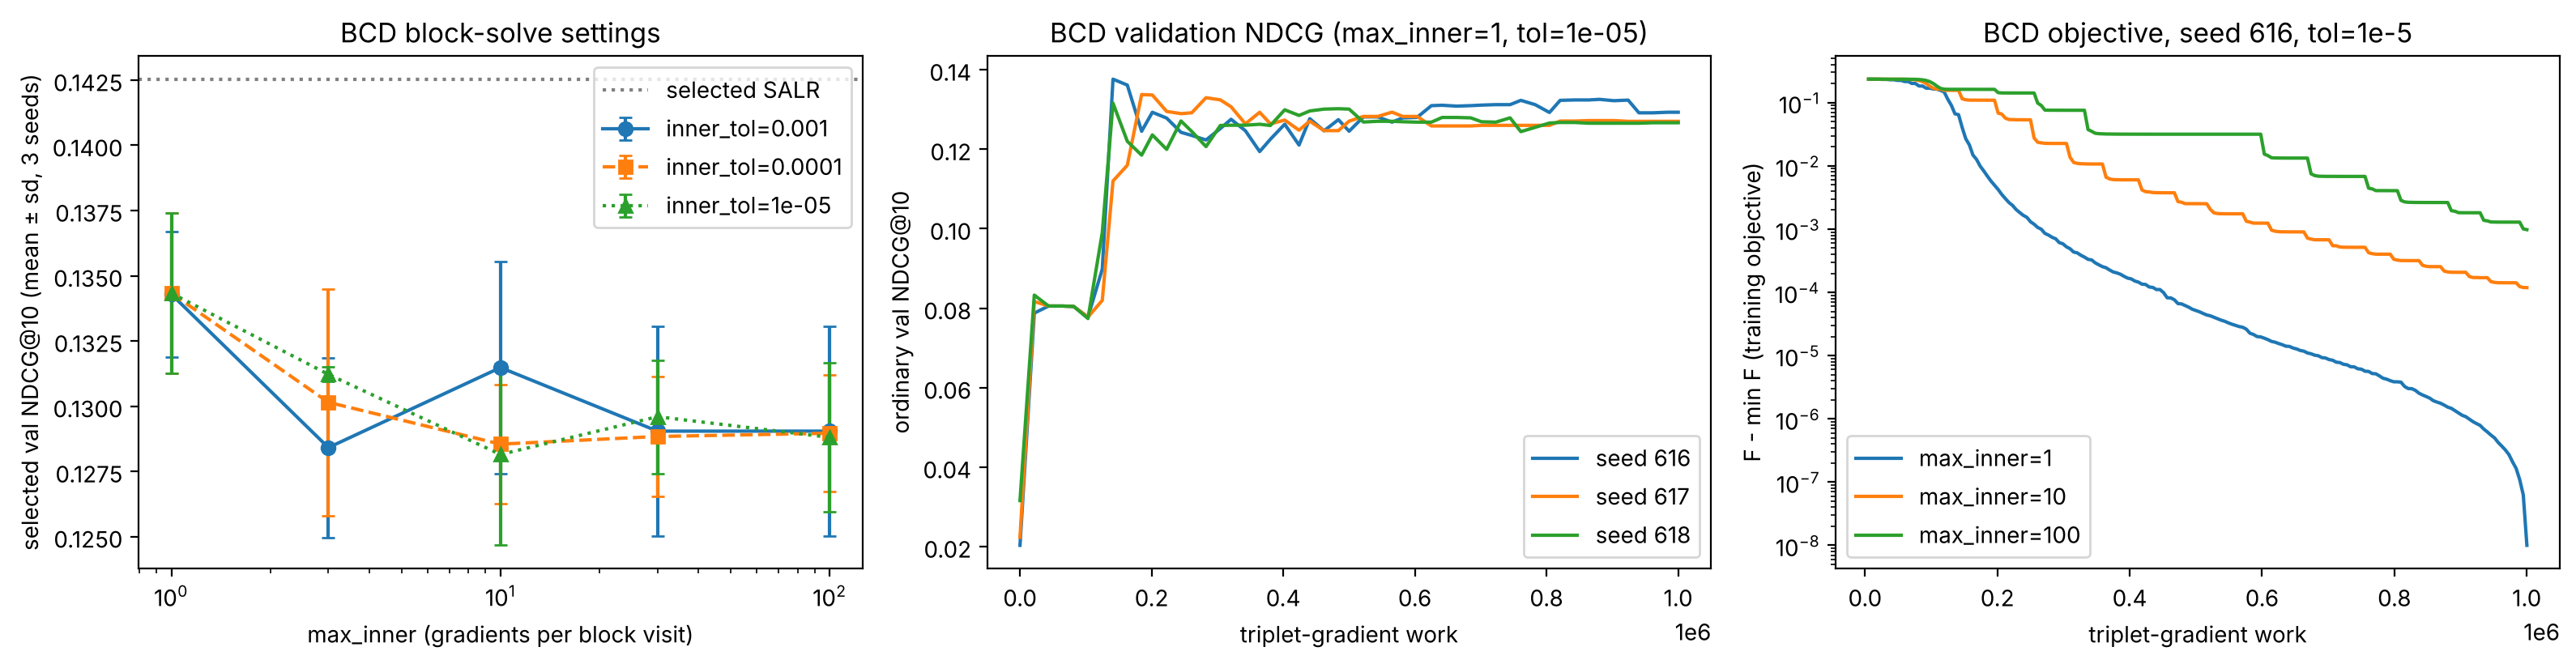

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for tol, style in ((1e-3, "-o"), (1e-4, "--s"), (1e-5, ":^")):
    part = summary[summary.inner_tol == tol].sort_values("max_inner")
    axes[0].errorbar(part.max_inner, part.mean_ndcg, yerr=part.std_ndcg, fmt=style, capsize=3,
                     label=f"inner_tol={tol:g}")
axes[0].axhline(salr.mean_ndcg, color="grey", ls=":", label="selected SALR")
axes[0].set(xscale="log", xlabel="max_inner (gradients per block visit)",
            ylabel="selected val NDCG@10 (mean ± sd, 3 seeds)", title="BCD block-solve settings")
axes[0].legend()

for seed in SEEDS:
    ck = logs[(chosen, seed)]["checkpoints"]
    axes[1].plot([c["work"] for c in ck], [c["val_ndcg"] for c in ck], label=f"seed {seed}")
axes[1].set(xlabel="triplet-gradient work", ylabel="ordinary val NDCG@10",
            title=f"BCD validation NDCG (max_inner={chosen.max_inner}, tol={chosen.inner_tol:g})")
axes[1].legend()

f_min = min(min(l["objective"]) for l in logs.values())
for m, color in zip((1, 10, 100), ("C0", "C1", "C2")):
    log = logs[(BCDConfig(LAMBDA_F, LAMBDA_W, inner_tol=1e-5, max_inner=m), 616)]
    axes[2].semilogy(log["work"], np.array(log["objective"]) - f_min + 1e-8, color=color,
                     label=f"max_inner={m}")
axes[2].set(xlabel="triplet-gradient work", ylabel="F - min F (training objective)",
            title="BCD objective, seed 616, tol=1e-5")
axes[2].legend()
fig.tight_layout(); fig.savefig(RESULTS / "bcd_tuning.png", dpi=150)

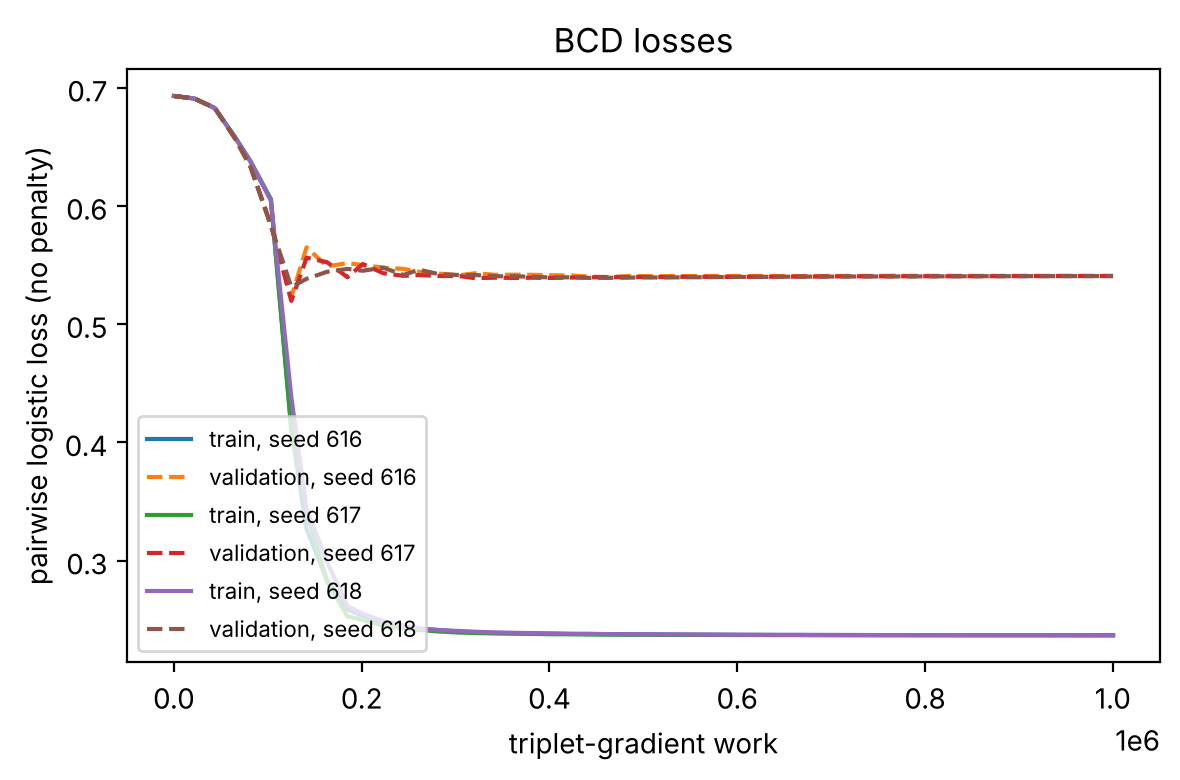

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
for seed in SEEDS:
    ck = logs[(chosen, seed)]["checkpoints"]
    ax.plot([c["work"] for c in ck], [c["train_loss"] for c in ck], label=f"train, seed {seed}")
    ax.plot([c["work"] for c in ck], [c["val_loss"] for c in ck], "--", label=f"validation, seed {seed}")
ax.set(xlabel="triplet-gradient work", ylabel="pairwise logistic loss (no penalty)", title="BCD losses")
ax.legend(fontsize=8); fig.tight_layout(); fig.savefig(RESULTS / "bcd_losses.png", dpi=150)